In [1]:
import time

import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import TextVectorization, Embedding, SimpleRNN, LSTM, GRU, Dense

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
df = pd.read_excel("./datasets/IMDB Dataset.xlsx")
print(df.head())
print(df.shape)
print(df.info())

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
None


In [3]:
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})
df.head()

,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.1, random_state=42, stratify=df["label"])

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

print(f"X_train : {X_train.shape}")
print(f"X_val : {X_val.shape}")
print(f"X_test : {X_test.shape}")

X_train : (36000,)
X_val : (9000,)
X_test : (5000,)


In [5]:
VOCAB, MAXLEN = 10000, 200
vectorizer = TextVectorization(max_tokens=VOCAB, output_sequence_length=MAXLEN)
vectorizer.adapt(X_train.values)                 # learn vocabulary from train only

X_train_seq = vectorizer(X_train.values).numpy()
X_val_seq = vectorizer(X_val.values).numpy()
X_test_seq = vectorizer(X_test.values).numpy()

In [6]:
def build_model(rnn_layer):
    return Sequential([
        Embedding(VOCAB, 64, mask_zero=True),
        rnn_layer(64),
        Dense(1, activation="sigmoid")
    ])

In [7]:
layers = {"RNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}
models, histories, results = {}, {}, []

In [8]:
for name, layer in layers.items():
    print(f"\n===== Training {name} =====")
    model = build_model(layer)
    model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

    start = time.time()
    history = model.fit(X_train_seq, y_train, epochs=5, batch_size=128,
                        validation_data=(X_val_seq, y_val), verbose=1)
    train_time = time.time() - start

    y_pred = (model.predict(X_test_seq) > 0.5).astype(int).ravel()
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Train Time (s)": train_time,
        "Parameters": model.count_params()
    })
    models[name], histories[name] = model, history.history
    histories[name]["y_pred"] = y_pred
results_df = pd.DataFrame(results).set_index("Model")
print("\n", results_df.round(4))


===== Training RNN =====
Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 17s 54ms/step - accuracy: 0.5769 - loss: 0.6699 - val_accuracy: 0.6029 - val_loss: 0.6457
Epoch 2/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step - accuracy: 0.7682 - loss: 0.4818 - val_accuracy: 0.7976 - val_loss: 0.4467
Epoch 3/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 16s 56ms/step - accuracy: 0.8692 - loss: 0.3200 - val_accuracy: 0.8436 - val_loss: 0.3984
Epoch 4/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.9060 - loss: 0.2376 - val_accuracy: 0.8393 - val_loss: 0.4109
Epoch 5/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.9554 - loss: 0.1243 - val_accuracy: 0.7972 - val_loss: 0.5474
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step

===== Training LSTM =====
Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 46s 157ms/step - accuracy: 0.7933 - loss: 0.4296 - val_accuracy: 0.8602 - val_loss: 0.3403
Epoch 2/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 44s 156ms/step - accuracy: 0.8892 - loss: 0.2798 - val_accuracy: 0.8718 - val_loss: 0.3114


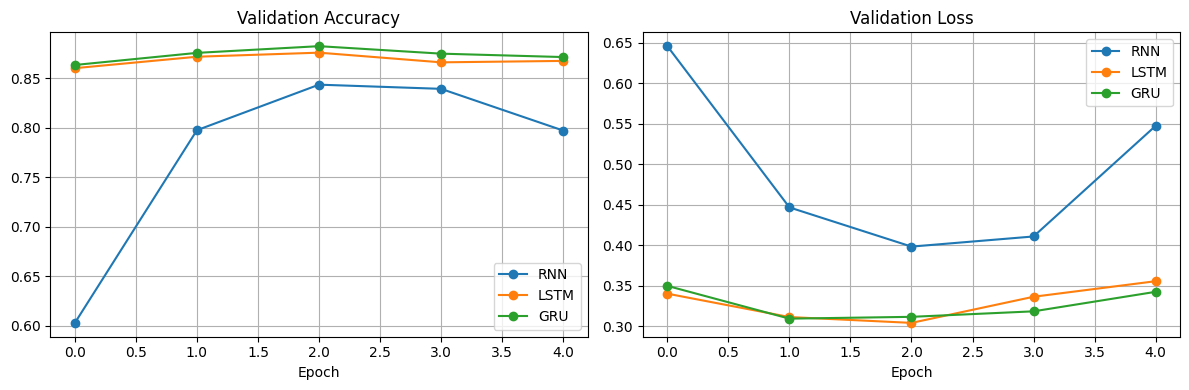

In [9]:
# (a) Validation accuracy and loss curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in layers:
    ax[0].plot(histories[name]["val_accuracy"], marker="o", label=name)
    ax[1].plot(histories[name]["val_loss"], marker="o", label=name)
ax[0].set_title("Validation Accuracy"); ax[1].set_title("Validation Loss")
for a in ax:
    a.set_xlabel("Epoch");
    a.legend();
    a.grid(True)
plt.tight_layout(); plt.show()

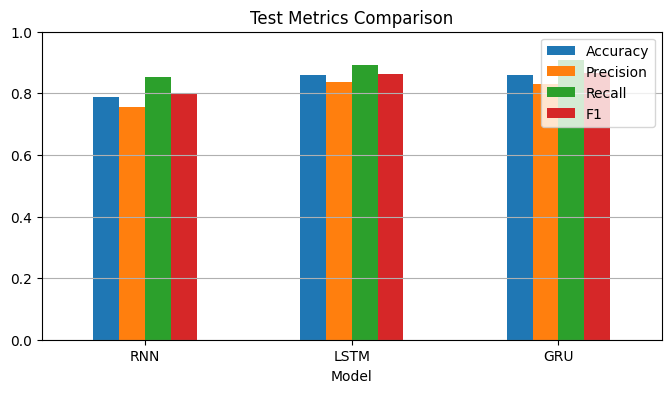

In [10]:
# (b) Test metrics bar chart
results_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(8, 4))
plt.title("Test Metrics Comparison");
plt.ylim(0, 1); 
plt.xticks(rotation=0)
plt.grid(axis="y"); 
plt.show()

In [11]:
# ---------- 7. Prediction function ----------
def predict_sentiment(text, model_name="LSTM"):
    seq = vectorizer([text]).numpy()
    prob = models[model_name].predict(seq, verbose=0)[0][0]
    label = "Positive" if prob > 0.5 else "Negative"
    return f"{model_name}: {label} (confidence = {max(prob, 1 - prob):.2f})"

In [14]:
for name in layers:
    print(predict_sentiment("The plot was dull but the music was great", name))

RNN: Negative (confidence = 0.95)
LSTM: Negative (confidence = 0.75)
GRU: Negative (confidence = 0.78)


In [15]:
for name in layers:
    print(predict_sentiment("Worst film ever. Boring and a complete waste of time.", name))

RNN: Negative (confidence = 1.00)
LSTM: Negative (confidence = 1.00)
GRU: Negative (confidence = 1.00)


In [16]:
for name in layers:
    print(predict_sentiment("This movie was absolutely fantastic, loved the acting!", name))

RNN: Negative (confidence = 0.73)
LSTM: Positive (confidence = 0.64)
GRU: Positive (confidence = 0.81)
